# CIFAR-10 CNN for Webots Object Classification
**Applied Robotics & AI Project — Part 2 (Assignments 3, 4, 5)**
BEng (Hons) Robotics and Artificial Intelligence — University of Hertfordshire

This notebook builds the deep-learning side of the project **off-robot** (on Colab GPU), exactly as the brief suggests, and produces every output the brief asks for:

| # | Required output | Section |
|---|---|---|
| 1 | Show all the layers of the model | §4 |
| 2 | Show the accuracy score | §5 |
| 3 | Predictions on **three images of your own** | §7 |
| 4 | Prediction on an image from the **Webots robot camera** | §8 |
| + | Optimisation proposal backed by numbers (TFLite / INT8 quantisation, latency, size) | §9 |

> **Run on Colab:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. Everything downloads automatically; training takes ~5 min on a T4.

## 1. Setup

In [1]:
import os, json, time, glob
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in str(get_ipython()) if 'get_ipython' in globals() else False
FORCE_TRAIN = False          # set True to retrain even if a saved model exists
SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)

for d in ['models', 'figures', 'results', 'own_images', 'webots_images']:
    os.makedirs(d, exist_ok=True)

print('TensorFlow', tf.__version__, '| Colab:', IN_COLAB)
print('Devices:', [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow 2.16.2 | Colab: False
Devices: ['CPU']


## 2. The CIFAR-10 dataset
60,000 colour images (32×32×3) in 10 classes — 50,000 for training and 10,000 for testing (Krizhevsky, 2009).
We hold out the last 5,000 training images as a **validation set** so the test set is only used once, for the final score (the original `cnn_v3` notebook validated on the test set, which leaks information into model selection).

train (45000, 32, 32, 3) | val (5000, 32, 32, 3) | test (10000, 32, 32, 3)


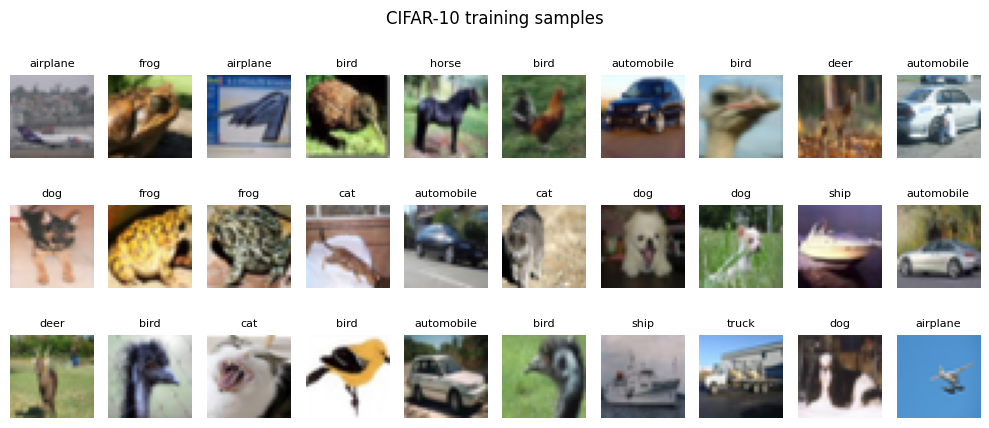

In [2]:
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

def load_cifar10():
    """Local runs: cached cifar10.npz. Otherwise the Hugging Face mirror of CIFAR-10 (seconds, versus
    ~15+ min from the original Toronto server), falling back to the standard Keras download."""
    if os.path.exists('cifar10.npz'):
        d = np.load('cifar10.npz')
        return (d['x_train'], d['y_train']), (d['x_test'], d['y_test'])
    try:
        import io, urllib.request, pyarrow.parquet as pq
        from PIL import Image
        base = 'https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/'
        splits = []
        for split in ('train', 'test'):
            table = pq.read_table(io.BytesIO(urllib.request.urlopen(base + f'{split}-00000-of-00001.parquet').read())).to_pydict()
            x = np.stack([np.array(Image.open(io.BytesIO(r['bytes'])).convert('RGB')) for r in table['img']])
            y = np.array(table['label'], dtype=np.uint8).reshape(-1, 1)
            splits.append((x, y))
        print('CIFAR-10 loaded from the Hugging Face mirror')
        return splits[0], splits[1]
    except Exception as e:
        print('Mirror unavailable (', e, ') - using the Keras download')
        return keras.datasets.cifar10.load_data()

(x_train_full, y_train_full), (x_test, y_test) = load_cifar10()
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_train_full, y_test = y_train_full.flatten(), y_test.flatten()

x_train, y_train = x_train_full[:45000], y_train_full[:45000]
x_val,   y_val   = x_train_full[45000:], y_train_full[45000:]
print('train', x_train.shape, '| val', x_val.shape, '| test', x_test.shape)

plt.figure(figsize=(10, 4.6))
for i in range(30):
    plt.subplot(3, 10, i + 1)
    plt.imshow(x_train[i]); plt.axis('off')
    plt.title(CLASS_NAMES[y_train[i]], fontsize=8)
plt.suptitle('CIFAR-10 training samples')
plt.tight_layout(); plt.savefig('figures/cifar_samples.png', dpi=160, bbox_inches='tight'); plt.show()

## 3. Baseline — the original `cnn_v3` model
3 convolution layers + 2 dense layers, trained 10 epochs with SGD and then 10 more with Adam (as in `cnn_v3.ipynb`). This is our reference point.

In [3]:
def build_baseline():
    m = models.Sequential(name='baseline_cnn_v3')
    m.add(keras.Input(shape=(32, 32, 3)))
    m.add(layers.Conv2D(32, (3, 3), activation='relu'))
    m.add(layers.MaxPooling2D((2, 2)))
    m.add(layers.Conv2D(64, (3, 3), activation='relu'))
    m.add(layers.MaxPooling2D((2, 2)))
    m.add(layers.Conv2D(64, (3, 3), activation='relu'))
    m.add(layers.Flatten())
    m.add(layers.Dense(64, activation='relu'))
    m.add(layers.Dense(10))
    return m

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

if os.path.exists('results/baseline.json') and not FORCE_TRAIN:
    baseline = json.load(open('results/baseline.json'))
    print('Loaded saved baseline results')
else:
    base = build_baseline()
    base.compile(optimizer='sgd', loss=loss_fn, metrics=['accuracy'])
    h1 = base.fit(x_train, y_train, epochs=10, batch_size=32, validation_data=(x_val, y_val), verbose=2)
    base.compile(optimizer='adam', loss=loss_fn, metrics=['accuracy'])
    h2 = base.fit(x_train, y_train, epochs=10, batch_size=32, validation_data=(x_val, y_val), verbose=2)
    _, acc = base.evaluate(x_test, y_test, verbose=0)
    baseline = {
        'acc': h1.history['accuracy'] + h2.history['accuracy'],
        'val_acc': h1.history['val_accuracy'] + h2.history['val_accuracy'],
        'test_acc': float(acc), 'params': int(base.count_params())}
    json.dump(baseline, open('results/baseline.json', 'w'))
print(f"Baseline test accuracy: {baseline['test_acc']*100:.2f}%  ({baseline['params']:,} parameters)")

Loaded saved baseline results
Baseline test accuracy: 64.73%  (122,570 parameters)


## 4. Improved CNN — architecture (all layers)
Design choices, each addressing a weakness of the baseline:
* **Three VGG-style blocks** (two 3×3 convolutions per block, *same* padding) — deeper features without shrinking the 32×32 image too early (Simonyan & Zisserman, 2015).
* **Batch Normalisation** after every convolution — faster, more stable training (Ioffe & Szegedy, 2015).
* **Dropout** that grows with depth (0.2 → 0.5) — fights the over-fitting seen in the baseline (Srivastava et al., 2014).
* **Data augmentation** (random flips & shifts) in the input pipeline — the robot sees objects from varied positions.
* **Logits output** (no softmax) — numerically stable loss; softmax is applied at inference.

In [4]:
def conv_block(m, filters, drop):
    for _ in range(2):
        m.add(layers.Conv2D(filters, (3, 3), padding='same', use_bias=False))
        m.add(layers.BatchNormalization())
        m.add(layers.Activation('relu'))
    m.add(layers.MaxPooling2D((2, 2)))
    m.add(layers.Dropout(drop))

def build_improved():
    m = models.Sequential(name='improved_cnn')
    m.add(keras.Input(shape=(32, 32, 3)))
    conv_block(m, 32, 0.2)
    conv_block(m, 64, 0.3)
    conv_block(m, 128, 0.4)
    m.add(layers.Flatten())
    m.add(layers.Dense(128, use_bias=False))
    m.add(layers.BatchNormalization())
    m.add(layers.Activation('relu'))
    m.add(layers.Dropout(0.5))
    m.add(layers.Dense(10, name='logits'))
    return m

model = build_improved()
model.summary()

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [5]:
# Layer table (saved for the report / slides)
rows = []
for i, l in enumerate(model.layers, 1):
    rows.append({'#': i, 'layer': l.__class__.__name__, 'name': l.name,
                 'output': str(tuple(l.output.shape[1:])), 'params': int(l.count_params())})
json.dump(rows, open('results/layers.json', 'w'), indent=1)
print(f"{'#':>2}  {'Layer':<20}{'Output shape':<18}{'Params':>8}")
for r in rows:
    print(f"{r['#']:>2}  {r['layer']:<20}{r['output']:<18}{r['params']:>8,}")
print('Total parameters:', f'{model.count_params():,}')

 #  Layer               Output shape        Params
 1  Conv2D              (32, 32, 32)           864
 2  BatchNormalization  (32, 32, 32)           128
 3  Activation          (32, 32, 32)             0
 4  Conv2D              (32, 32, 32)         9,216
 5  BatchNormalization  (32, 32, 32)           128
 6  Activation          (32, 32, 32)             0
 7  MaxPooling2D        (16, 16, 32)             0
 8  Dropout             (16, 16, 32)             0
 9  Conv2D              (16, 16, 64)        18,432
10  BatchNormalization  (16, 16, 64)           256
11  Activation          (16, 16, 64)             0
12  Conv2D              (16, 16, 64)        36,864
13  BatchNormalization  (16, 16, 64)           256
14  Activation          (16, 16, 64)             0
15  MaxPooling2D        (8, 8, 64)               0
16  Dropout             (8, 8, 64)               0
17  Conv2D              (8, 8, 128)         73,728
18  BatchNormalization  (8, 8, 128)            512
19  Activation          (8, 8, 

## 5. Training and accuracy score
Adam (lr = 1e-3), batch 64, up to 40 epochs with **ReduceLROnPlateau** and **EarlyStopping** on validation accuracy (best weights restored).

In [6]:
AUTOTUNE = tf.data.AUTOTUNE
augment = keras.Sequential([layers.RandomFlip('horizontal'),
                            layers.RandomTranslation(0.1, 0.1, fill_mode='reflect')])

train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(10000, seed=SEED).batch(64)
            .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(256).prefetch(AUTOTUNE)

MODEL_PATH = 'models/cifar10_cnn.keras'
if os.path.exists(MODEL_PATH) and os.path.exists('results/history.json') and not FORCE_TRAIN:
    model = keras.models.load_model(MODEL_PATH)
    history = json.load(open('results/history.json'))
    print('Loaded trained model from', MODEL_PATH)
else:
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'])
    cbs = [keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=3, min_lr=1e-5),
           keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(train_ds, epochs=40, validation_data=val_ds, callbacks=cbs, verbose=2)
    history = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    history['train_time_s'] = time.time() - t0
    model.save(MODEL_PATH)
    json.dump(history, open('results/history.json', 'w'))

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f'\n>>> Improved CNN TEST ACCURACY: {test_acc*100:.2f}%   (baseline {baseline["test_acc"]*100:.2f}%)')

Loaded trained model from models/cifar10_cnn.keras



>>> Improved CNN TEST ACCURACY: 86.55%   (baseline 64.73%)


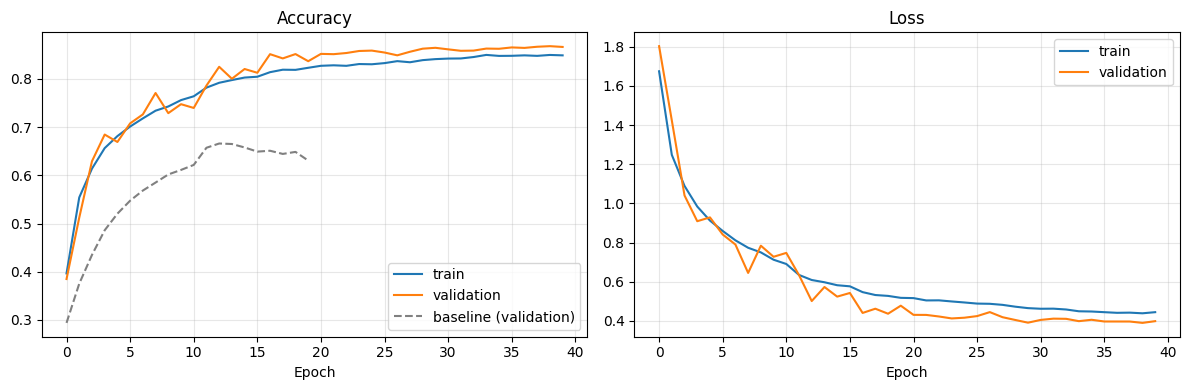

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['accuracy'], label='train'); ax[0].plot(history['val_accuracy'], label='validation')
ax[0].plot(baseline['val_acc'], '--', color='grey', label='baseline (validation)')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(history['loss'], label='train'); ax[1].plot(history['val_loss'], label='validation')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures/training_curves.png', dpi=160, bbox_inches='tight'); plt.show()

## 6. Evaluation — confusion matrix, per-class accuracy and errors

              precision    recall  f1-score   support

    airplane      0.874     0.887     0.880      1000
  automobile      0.941     0.950     0.945      1000
        bird      0.838     0.773     0.804      1000
         cat      0.809     0.668     0.732      1000
        deer      0.857     0.849     0.853      1000
         dog      0.821     0.794     0.807      1000
        frog      0.776     0.962     0.859      1000
       horse      0.917     0.894     0.905      1000
        ship      0.926     0.933     0.929      1000
       truck      0.903     0.945     0.924      1000

    accuracy                          0.866     10000
   macro avg      0.866     0.865     0.864     10000
weighted avg      0.866     0.866     0.864     10000



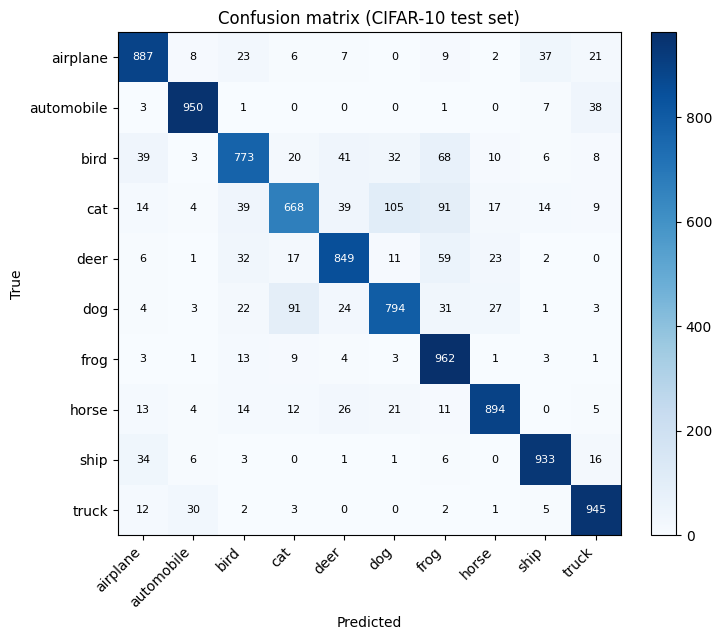

Top confusions (true -> predicted, count): [('cat', 'dog', 105), ('cat', 'frog', 91), ('dog', 'cat', 91), ('bird', 'frog', 68), ('deer', 'frog', 59)]


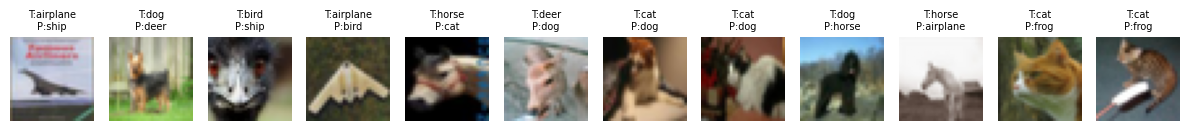

In [8]:
from sklearn.metrics import confusion_matrix, classification_report
logits = model.predict(x_test, batch_size=512, verbose=0)
y_pred = logits.argmax(1)
cm = confusion_matrix(y_test, y_pred)
per_class = cm.diagonal() / cm.sum(1)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

plt.figure(figsize=(7.5, 6.5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(10), CLASS_NAMES, rotation=45, ha='right'); plt.yticks(range(10), CLASS_NAMES)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (CIFAR-10 test set)')
plt.colorbar(fraction=0.046); plt.tight_layout()
plt.savefig('figures/confusion_matrix.png', dpi=160, bbox_inches='tight'); plt.show()

# most frequent confusions
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
confusions = [(CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j])) for i, j in top]
print('Top confusions (true -> predicted, count):', confusions)

wrong = np.where(y_pred != y_test)[0][:12]
plt.figure(figsize=(12, 3))
for k, i in enumerate(wrong):
    plt.subplot(1, 12, k + 1); plt.imshow(x_test[i]); plt.axis('off')
    plt.title(f'T:{CLASS_NAMES[y_test[i]]}\nP:{CLASS_NAMES[y_pred[i]]}', fontsize=7)
plt.tight_layout(); plt.savefig('figures/misclassified.png', dpi=160, bbox_inches='tight'); plt.show()

json.dump({'test_acc': float(test_acc), 'test_loss': float(test_loss),
           'params': int(model.count_params()), 'epochs': len(history['accuracy']),
           'train_time_s': history.get('train_time_s'),
           'per_class': dict(zip(CLASS_NAMES, map(float, per_class))),
           'top_confusions': confusions, 'baseline_test_acc': baseline['test_acc'],
           'baseline_params': baseline['params']},
          open('results/metrics.json', 'w'), indent=1)

## 7. Predictions on three images of my own
Three photos (a car, a bird, a ship) are fetched automatically from the project's GitHub repository into `own_images/`. To test your own, drop JPGs into that folder.
The photo is downsampled to 32×32 with **area (anti-aliased) interpolation**, then the top-3 classes are shown.
We also report the original `cnn_v3` method (`load_img(target_size=...)`, nearest-neighbour), which aliases a 960-px photo badly.

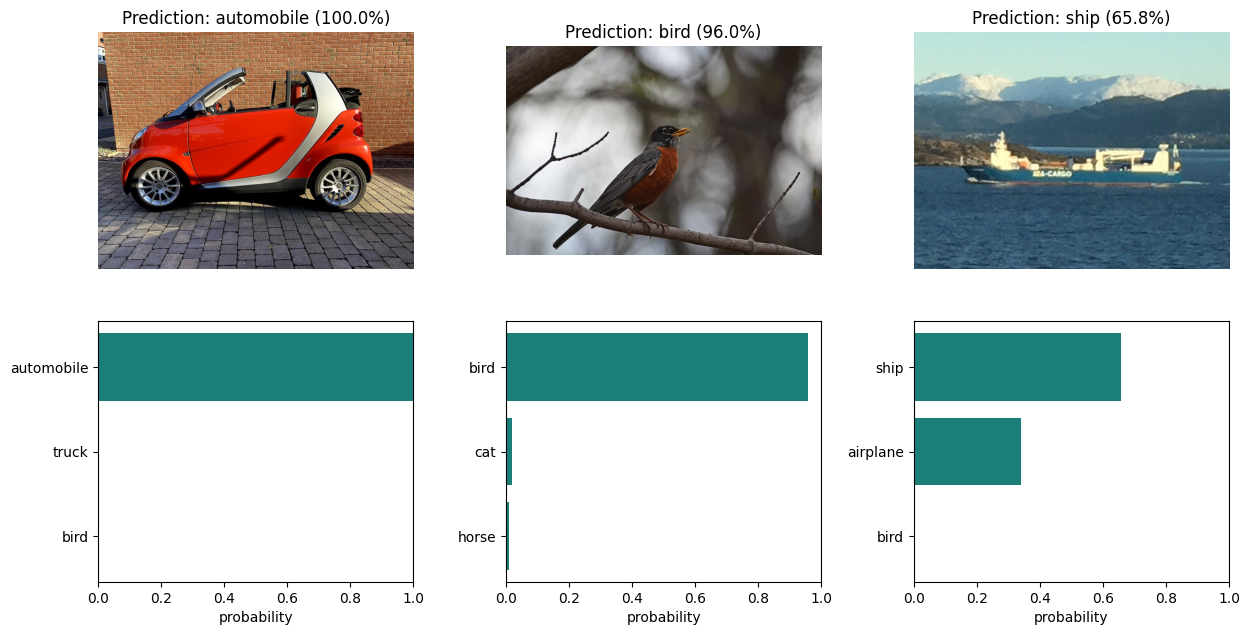

1_car.jpg    anti-aliased -> automobile 100.0%   |  naive nearest-neighbour -> deer 35.7%
2_bird.jpg   anti-aliased -> bird        96.0%   |  naive nearest-neighbour -> bird 52.6%
3_ship.jpg   anti-aliased -> ship        65.8%   |  naive nearest-neighbour -> airplane 79.1%


In [9]:
def load_image(path, method='area'):
    # 'area' = anti-aliased downsampling (each output pixel averages the pixels it covers), like CIFAR-10.
    # The original cnn_v3 used load_img(target_size=(32,32)), i.e. 'nearest': it skips 29 of every 30 pixels.
    a = keras.utils.img_to_array(keras.utils.load_img(path))
    return tf.image.resize(a, (32, 32), method=method).numpy()[None] / 255.0

def predict_file(path, method='area'):
    return tf.nn.softmax(model.predict(load_image(path, method), verbose=0)[0]).numpy()

REPO = 'https://raw.githubusercontent.com/dharshanthehacker-arch/epuck-cnn-webots/main/notebook/'
def fetch_from_repo(folder, names):
    """Download the project's images from the public GitHub repository (no manual upload needed)."""
    import urllib.request
    for n in names:
        if not os.path.exists(os.path.join(folder, n)):
            urllib.request.urlretrieve(REPO + folder + '/' + n, os.path.join(folder, n))

if not glob.glob('own_images/*.jpg'):
    fetch_from_repo('own_images', ['1_car.jpg', '2_bird.jpg', '3_ship.jpg'])

own = sorted(glob.glob('own_images/*.jpg') + glob.glob('own_images/*.jpeg') + glob.glob('own_images/*.png'))[:3]
own_results = []
if not own:
    print('No own images found - upload three photos to own_images/'); own = []
fig, axes = (None, None) if not own else plt.subplots(2, len(own), figsize=(4.2 * len(own), 7), gridspec_kw={'height_ratios': [3, 2]})
for k, path in enumerate(own):
    p = predict_file(path)
    top3 = p.argsort()[::-1][:3]
    p_naive = predict_file(path, 'nearest')
    own_results.append({'file': os.path.basename(path), 'pred': CLASS_NAMES[top3[0]],
                        'naive_pred': CLASS_NAMES[int(p_naive.argmax())], 'naive_conf': float(p_naive.max()),
                        'conf': float(p[top3[0]]),
                        'top3': [(CLASS_NAMES[i], float(p[i])) for i in top3]})
    axes[0, k].imshow(plt.imread(path)); axes[0, k].axis('off')
    axes[0, k].set_title(f'Prediction: {CLASS_NAMES[top3[0]]} ({p[top3[0]]*100:.1f}%)')
    axes[1, k].barh([CLASS_NAMES[i] for i in top3[::-1]], p[top3[::-1]], color='#1b7f79')
    axes[1, k].set_xlim(0, 1); axes[1, k].set_xlabel('probability')
if own:
    plt.tight_layout(); plt.savefig('figures/own_predictions.png', dpi=160, bbox_inches='tight'); plt.show()
json.dump(own_results, open('results/own_predictions.json', 'w'), indent=1)
for r in own_results:
    print(f"{r['file']:<12} anti-aliased -> {r['pred']:<10} {r['conf']*100:5.1f}%   |  naive nearest-neighbour -> {r['naive_pred']} {r['naive_conf']*100:.1f}%")

## 8. Prediction on images from the Webots robot camera
The e-puck controller (`epuck_vision_cnn.py`, *tour* mode) drives up to each miniature object in the arena and saves its 320×240 camera frame to `captures/tour/`.
They are fetched automatically from the GitHub repository into `webots_images/`.

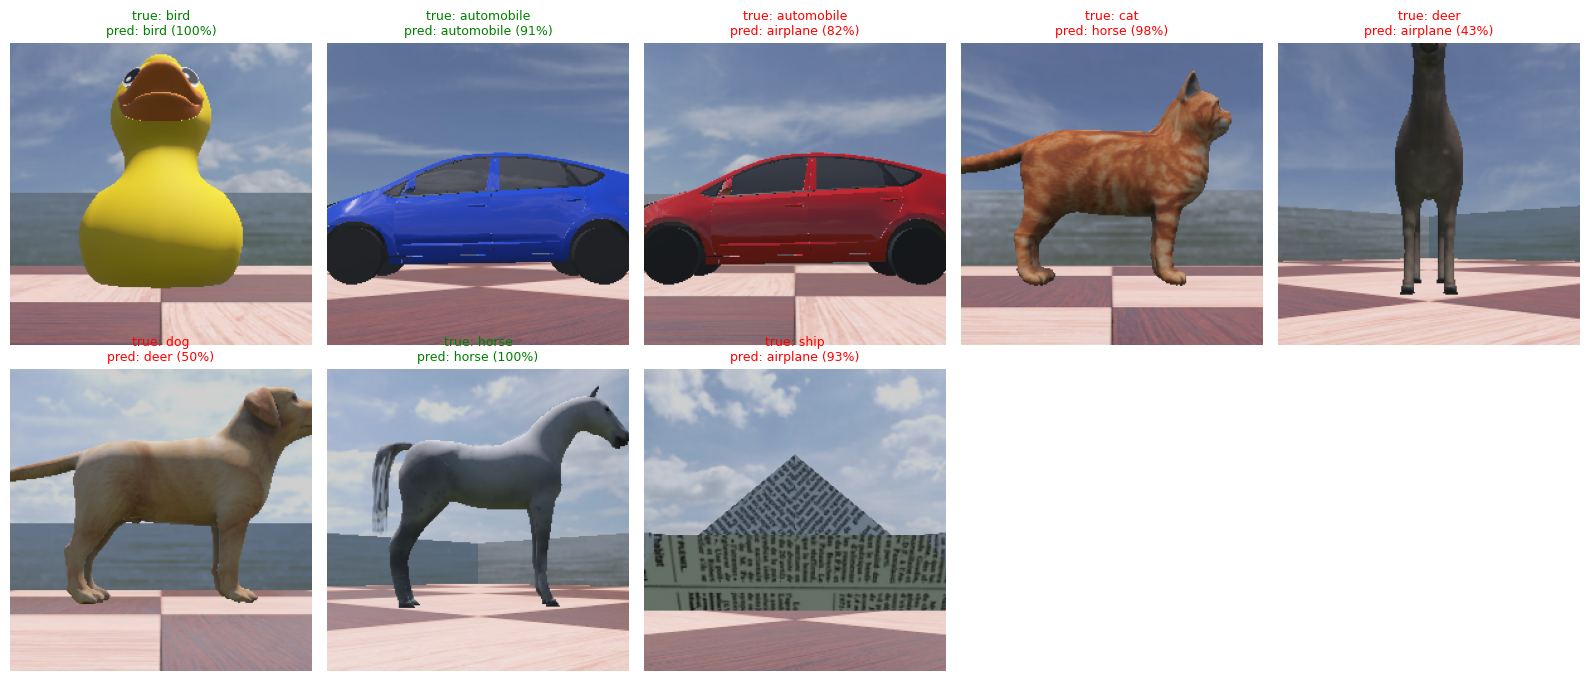

Webots camera accuracy: 38% on 8 images


In [10]:
if not glob.glob('webots_images/*.png'):
    fetch_from_repo('webots_images', ['bird_1__bird.png', 'car_blue__automobile.png', 'car_red__automobile.png',
                                      'cat__cat.png', 'deer__deer.png', 'dog__dog.png', 'horse__horse.png', 'ship__ship.png'])

def centre_crop_load(path):
    img = keras.utils.load_img(path); a = keras.utils.img_to_array(img)
    h, w = a.shape[:2]; s = min(h, w)
    a = a[(h - s)//2:(h - s)//2 + s, (w - s)//2:(w - s)//2 + s]
    return tf.image.resize(a, (32, 32), method='area').numpy()[None] / 255.0, a / 255.0

webots = sorted(glob.glob('webots_images/*.png'))
webots_results = []
if webots:
    n = len(webots); cols = min(n, 5); rows_ = int(np.ceil(n / cols))
    plt.figure(figsize=(3.2 * cols, 3.4 * rows_))
    for k, path in enumerate(webots):
        x, shown = centre_crop_load(path)
        p = tf.nn.softmax(model.predict(x, verbose=0)[0]).numpy(); i = int(p.argmax())
        truth = os.path.splitext(os.path.basename(path))[0].split('__')[-1]
        webots_results.append({'file': os.path.basename(path), 'truth': truth,
                               'pred': CLASS_NAMES[i], 'conf': float(p[i]),
                               'top3': [(CLASS_NAMES[j], float(p[j])) for j in p.argsort()[::-1][:3]]})
        plt.subplot(rows_, cols, k + 1); plt.imshow(shown); plt.axis('off')
        ok = CLASS_NAMES[i] == truth
        plt.title(f'true: {truth}\npred: {CLASS_NAMES[i]} ({p[i]*100:.0f}%)', fontsize=9,
                  color='green' if ok else 'red')
    plt.tight_layout(); plt.savefig('figures/webots_predictions.png', dpi=160, bbox_inches='tight'); plt.show()
    json.dump(webots_results, open('results/webots_predictions_notebook.json', 'w'), indent=1)
    acc = np.mean([r['truth'] == r['pred'] for r in webots_results])
    print(f'Webots camera accuracy: {acc*100:.0f}% on {len(webots_results)} images')
else:
    print('No Webots images found yet - run the tour world first.')

## 9. Optimisation for on-robot use — TensorFlow Lite & quantisation
Running a Keras model inside the robot's control loop risks stalling motor commands. We convert the trained model to **TensorFlow Lite** with three precisions and measure what matters on a robot: **file size, single-image latency and accuracy**.
* **float32 TFLite** — same maths, lighter runtime
* **float16** — weights halved in size
* **INT8 full-integer** — weights *and* activations in 8-bit, calibrated on 300 training images (Jacob et al., 2018)

INFO:tensorflow:Assets written to: models/saved_model/assets


INFO:tensorflow:Assets written to: models/saved_model/assets


Saved artifact at 'models/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  5806940000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807004832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807005536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807002016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807003600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807095120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807163168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807163872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5806959600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807161936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5807371360: TensorSpec(shape=(), dtype=tf.resource, name=None)

W0000 00:00:1794977402.679066 1084794 tf_tfl_flatbuffer_helpers.cc:390] Ignored output_format.
W0000 00:00:1794977402.679233 1084794 tf_tfl_flatbuffer_helpers.cc:393] Ignored drop_control_dependency.
2026-11-18 12:50:02.679853: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: models/saved_model
2026-11-18 12:50:02.680406: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-11-18 12:50:02.680409: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: models/saved_model
2026-11-18 12:50:02.689040: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:388] MLIR V1 optimization pass is not enabled
2026-11-18 12:50:02.690098: I tensorflow/cc/saved_model/loader.cc:234] Restoring SavedModel bundle.
2026-11-18 12:50:02.727721: I tensorflow/cc/saved_model/loader.cc:218] Running initialization op on SavedModel bundle at path: models/saved_model
2026-11-18 12:50:02.737098: I tensorflow/cc/saved_model/loa

W0000 00:00:1794977408.284584 1084794 tf_tfl_flatbuffer_helpers.cc:390] Ignored output_format.
W0000 00:00:1794977408.284592 1084794 tf_tfl_flatbuffer_helpers.cc:393] Ignored drop_control_dependency.
2026-11-18 12:50:08.284688: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: models/saved_model
2026-11-18 12:50:08.285242: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-11-18 12:50:08.285245: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: models/saved_model
2026-11-18 12:50:08.294185: I tensorflow/cc/saved_model/loader.cc:234] Restoring SavedModel bundle.
2026-11-18 12:50:08.329618: I tensorflow/cc/saved_model/loader.cc:218] Running initialization op on SavedModel bundle at path: models/saved_model
2026-11-18 12:50:08.338786: I tensorflow/cc/saved_model/loader.cc:317] SavedModel load for tags { serve }; Status: success: OK. Took 54098 microseconds.


W0000 00:00:1794977413.962888 1084794 tf_tfl_flatbuffer_helpers.cc:390] Ignored output_format.
W0000 00:00:1794977413.962897 1084794 tf_tfl_flatbuffer_helpers.cc:393] Ignored drop_control_dependency.
2026-11-18 12:50:13.963016: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: models/saved_model
2026-11-18 12:50:13.963611: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-11-18 12:50:13.963615: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: models/saved_model
2026-11-18 12:50:13.972468: I tensorflow/cc/saved_model/loader.cc:234] Restoring SavedModel bundle.
2026-11-18 12:50:14.007380: I tensorflow/cc/saved_model/loader.cc:218] Running initialization op on SavedModel bundle at path: models/saved_model
2026-11-18 12:50:14.016805: I tensorflow/cc/saved_model/loader.cc:317] SavedModel load for tags { serve }; Status: success: OK. Took 53789 microseconds.


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


Model              Size (MB)  Latency (ms)  Max FPS  Accuracy
Keras (float32)         2.21          5.42      184    86.55%
TFLite float32          2.21          0.52     1939    86.55%
TFLite float16          1.11          0.52     1926    86.55%
TFLite int8             0.57          0.17     5802    86.64%


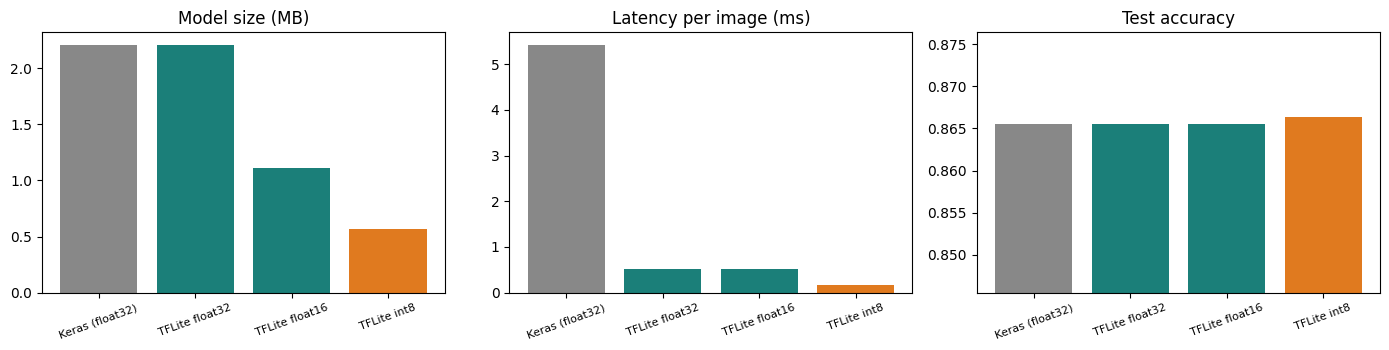

In [11]:
def rep_data():
    for i in range(300):
        yield [x_train[i:i + 1]]

model.export('models/saved_model')     # SavedModel route: robust with Keras 3

def convert(kind):
    c = tf.lite.TFLiteConverter.from_saved_model('models/saved_model')
    if kind == 'float16':
        c.optimizations = [tf.lite.Optimize.DEFAULT]; c.target_spec.supported_types = [tf.float16]
    elif kind == 'int8':
        c.optimizations = [tf.lite.Optimize.DEFAULT]; c.representative_dataset = rep_data
        c.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        c.inference_input_type = tf.int8; c.inference_output_type = tf.int8
    path = f'models/cifar10_cnn_{kind}.tflite'
    open(path, 'wb').write(c.convert())
    return path

def tflite_runner(path):
    it = tf.lite.Interpreter(model_path=path, num_threads=2); it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    def run(x):
        if inp['dtype'] == np.int8:
            s, z = inp['quantization']; x = np.clip(np.round(x / s + z), -128, 127).astype(np.int8)
        it.set_tensor(inp['index'], x); it.invoke(); y = it.get_tensor(out['index'])
        if out['dtype'] == np.int8:
            s, z = out['quantization']; y = (y.astype(np.float32) - z) * s
        return y
    return run

def bench(fn, n=300):
    x = x_test[:1]
    for _ in range(20): fn(x)
    t = time.perf_counter()
    for _ in range(n): fn(x)
    return (time.perf_counter() - t) / n * 1000

N_EVAL = 10000
results = {}
keras_fn = lambda x: model(x, training=False)
results['Keras (float32)'] = {'size_mb': model.count_params() * 4 / 1e6,   # weights only
                              'latency_ms': bench(keras_fn), 'acc': float(test_acc)}
for kind in ['float32', 'float16', 'int8']:
    path = convert(kind); run = tflite_runner(path)
    preds = np.array([run(x_test[i:i + 1])[0].argmax() for i in range(N_EVAL)])
    results[f'TFLite {kind}'] = {'size_mb': os.path.getsize(path) / 1e6, 'latency_ms': bench(run),
                                 'acc': float((preds == y_test[:N_EVAL]).mean())}
json.dump(results, open('results/optimisation.json', 'w'), indent=1)

print(f"{'Model':<18}{'Size (MB)':>10}{'Latency (ms)':>14}{'Max FPS':>9}{'Accuracy':>10}")
for k, v in results.items():
    print(f"{k:<18}{v['size_mb']:>10.2f}{v['latency_ms']:>14.2f}{1000/v['latency_ms']:>9.0f}{v['acc']*100:>9.2f}%")

names = list(results)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, key, title in zip(ax, ['size_mb', 'latency_ms', 'acc'], ['Model size (MB)', 'Latency per image (ms)', 'Test accuracy']):
    vals = [results[n][key] for n in names]
    a.bar(range(len(names)), vals, color=['#888', '#1b7f79', '#1b7f79', '#e07a1f'])
    a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=20, fontsize=8); a.set_title(title)
    if key == 'acc': a.set_ylim(min(vals) - 0.02, max(vals) + 0.01)
plt.tight_layout(); plt.savefig('figures/optimisation.png', dpi=160, bbox_inches='tight'); plt.show()

### Optimisation proposal (summary)
1. **Train off-robot, deploy INT8 TFLite on-robot** — ~4× smaller, faster, negligible accuracy loss (table above).
2. **Asynchronous inference** — the controller hands frames to a worker thread (queue length 1, frames dropped when busy), so `robot.step()` and the motors are never blocked.
3. **Event-triggered inference** — a cheap OpenCV pre-filter (saliency / IR proximity) decides *when* the CNN runs, instead of on every frame.
4. **ROI cropping** — only the 32×32 region around the object is classified.
5. **Next steps** — magnitude pruning (Han et al., 2016) + INT8, or a MobileNet/SSD detector on an edge accelerator (Coral TPU / Jetson) for full object *detection*.

## 10. Download the trained models

In [12]:
print(sorted(os.listdir('models')))
if IN_COLAB:
    from google.colab import files
    for f in os.listdir('models'):
        files.download(os.path.join('models', f))

['cifar10_cnn.keras', 'cifar10_cnn_float16.tflite', 'cifar10_cnn_float32.tflite', 'cifar10_cnn_int8.tflite', 'saved_model']
